# Assignment 1 - Linear Regression
Berkay Aydin & Elif Kanik

### Google Colab Notebook

The complete Google Colab notebook, including the code, outputs, and plots, is available here:

Notebook included in this repository

## 1. Data Collection and Preparation

For this assignment, we used Ford Ranger MSRP data from Cars.com. We collected the minimum and maximum prices from 2000 to 2011 and from 2019 to 2025.

There is no price data between 2012 and 2018 because the Ford Ranger was not produced during those years. We left these years out of the training data since we will use our regression models to estimate their prices later.

We also left 2026 out of the training data so we can predict its price range separately.

In [1]:
# Ford Ranger MSRP data from Cars.com

years = [
    2000, 2001, 2002, 2003, 2004, 2005,
    2006, 2007, 2008, 2009, 2010, 2011,
    2019, 2020, 2021, 2022, 2023, 2024, 2025
]

min_prices = [
    11580, 11960, 12565, 13645, 14575, 14610,
    14450, 13970, 14490, 16395, 17820, 18160,
    24000, 24110, 24820, 25980, 27400, 32820, 33350
]

max_prices = [
    19785, 24335, 25010, 25450, 26015, 26795,
    26670, 24425, 24350, 25805, 25800, 26070,
    38565, 38675, 39035, 39730, 40945, 55720, 56070
]

In [2]:
print("Number of years:", len(years))
print("Number of minimum prices:", len(min_prices))
print("Number of maximum prices:", len(max_prices))

Number of years: 19
Number of minimum prices: 19
Number of maximum prices: 19


## 2. Cost Function and Gradient Derivation

For both the minimum and maximum price models, we used the cost function given in the assignment:

J(theta) = (1/m) Σ[e² + 0.1e⁴]

where the prediction error for each data point is:

e = (theta0 + theta1*x) - y

The squared-error term penalizes prediction errors, while the fourth-power term makes larger errors have a much stronger effect on the total cost.

To use gradient descent, we first find how the cost changes with respect to the error:

dL/de = 2e + 0.4e³

For theta0:

de/dtheta0 = 1

so:

dJ/dtheta0 = (1/m) Σ(2e + 0.4e³)

For theta1:

de/dtheta1 = x

so:

dJ/dtheta1 = (1/m) Σ((2e + 0.4e³)x)

These are the gradients we use in the training functions to update theta0 and theta1.

## 3. Unscaled Models

We first trained the minimum and maximum price models using the original year values without feature scaling. Since the year values are around 2000, the gradient for theta1 becomes very large. Because of this, very small learning rates were needed to keep gradient descent stable.

### 3.1 Unscaled MIN-Price Model

In [3]:
def predict(x, theta0, theta1):
  return theta0 + x * theta1

In [4]:
print(predict(2000, 100, 10))

20100


In [5]:
def error(x, y, theta0, theta1):
  prediction = predict(x, theta0, theta1)
  error = prediction - y
  return error

In [6]:
print(error(2000, 11580, 100, 10))

8520


In [7]:
def cost_for_one(error):
  return error ** 2 + 0.1 * error ** 4

In [8]:
def cost(years, prices, theta0, theta1):

    total_cost = 0

    for i in range(len(years)):
        year_error = error(years[i], prices[i], theta0, theta1)
        year_cost = cost_for_one(year_error)
        total_cost += year_cost

    result = total_cost / len(years)

    return result

In [9]:
def gradients(years, prices, theta0, theta1):
  gradient_theta0 = 0
  gradient_theta1 = 0

  for i in range(len(years)):
    year_error = error(years[i], prices[i], theta0, theta1)
    derivative = 2 * year_error + 0.4 * year_error ** 3
    gradient_theta0 += derivative
    gradient_theta1 += derivative * years[i]

  gradient_theta0 /= len(years)
  gradient_theta1 /= len(years)

  return (gradient_theta0, gradient_theta1)

In [10]:
def train(years, prices, theta0, theta1, learning_rate, iterations):

    losses = []

    for i in range(iterations):

        gradient_theta0, gradient_theta1 = gradients(
            years, prices, theta0, theta1
        )

        theta0 = theta0 - learning_rate * gradient_theta0
        theta1 = theta1 - learning_rate * gradient_theta1

        new_cost = cost(years, prices, theta0, theta1)

        losses.append(new_cost)

    return (theta0, theta1, losses)

In [11]:
theta0 = 0
theta1 = 0

# A very small learning rate is used because the unscaled year values
# are around 2000, which makes the gradients very large.
learning_rate = 0.000000000000001

theta0, theta1, losses = train(years, min_prices, theta0, theta1, learning_rate, 100)

print("Final theta0:", theta0)
print("Final theta1:", theta1)
print("First loss:", losses[0])
print("Final loss:", losses[-1])

Final theta0: 0.005077178643133895
Final theta1: 10.42230772318602
First loss: 963421290600533.2
Final loss: 392325110089915.8


In [12]:
# Save this loss history before the same variable name is used by the MAX model
losses_unscaled_min = losses.copy()

In [13]:
import matplotlib.pyplot as plt

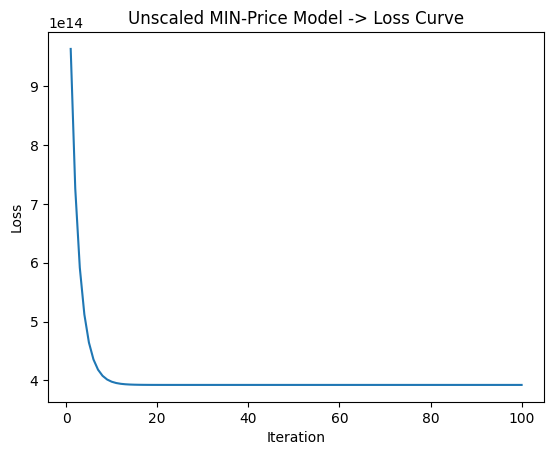

In [14]:
plt.plot(range(1, 101), losses)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Unscaled MIN-Price Model -> Loss Curve")

plt.show()

In [15]:
print("2000 prediction:", predict(2000, theta0, theta1))
print("2000 actual:", min_prices[0])

print("2025 prediction:", predict(2025, theta0, theta1))
print("2025 actual:", min_prices[-1])

2000 prediction: 20844.620523550682
2000 actual: 11580
2025 prediction: 21105.178216630335
2025 actual: 33350


In [16]:
gradient_theta0, gradient_theta1 = gradients(years, min_prices, 0, 0)

print("theta0 gradient:", gradient_theta0)
print("theta1 gradient:", gradient_theta1)

theta0 gradient: -4053116607789.4736
theta1 gradient: -8185467982864475.0


In [17]:
missing_years = [
    2012, 2013, 2014, 2015,
    2016, 2017, 2018
]

missing_min_prices = []

# Estimate the MIN price for each year when the Ranger was not produced
for year in missing_years:
    estimated_price = predict(year, theta0, theta1)
    missing_min_prices.append(estimated_price)

    print(year, estimated_price)

2012 20969.688216228915
2013 20980.110523952102
2014 20990.53283167529
2015 21000.955139398473
2016 21011.37744712166
2017 21021.799754844847
2018 21032.22206256803


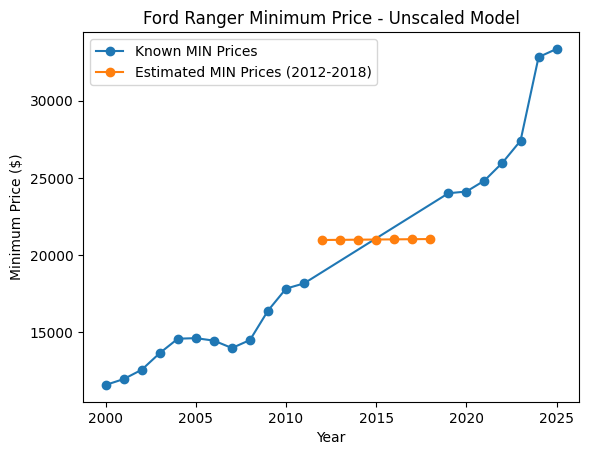

In [18]:
plt.plot(
    years,
    min_prices,
    marker="o",
    label="Known MIN Prices"
)

plt.plot(
    missing_years,
    missing_min_prices,
    marker="o",
    label="Estimated MIN Prices (2012-2018)"
)

plt.xlabel("Year")
plt.ylabel("Minimum Price ($)")
plt.title("Ford Ranger Minimum Price - Unscaled Model")
plt.legend()

plt.show()

### Unscaled MIN Model Observation

The loss decreased during training, so gradient descent was moving in the correct direction. However, the model still did not follow the actual price trend very closely. For example, its predictions for 2000 and 2025 were noticeably different from the real prices.

One reason is that we are using the raw year values directly. This creates very large gradients and forces us to use an extremely small learning rate. This result gave us a useful baseline to compare with the scaled model later.


### 3.2 Unscaled MAX-Price Model

In [19]:
def predict(x,theta0, theta1):
  prediction= theta0+ theta1*x
  return prediction
print(predict(2001,0.3,0.4))


800.7


In [20]:
def error (x,y, theta0, theta1):
  prediction= theta0+ theta1*x
  return prediction - y

print(error(2001,2453,0.3,0.4))


-1652.3


In [21]:
def cost_for_one(error):
  sqr_err= error**2
  return sqr_err + 0.1* (sqr_err**2)

print(cost_for_one(2))


5.6


In [22]:
def cost(years, prices, theta0, theta1):

    total_cost = 0

    for i in range(len(years)):
        year_error = error(years[i], prices[i], theta0, theta1)
        year_cost = cost_for_one(year_error)
        total_cost += year_cost

    result = total_cost / len(years)

    return result

year_error = error(2001, 2453, 0.3, 0.4)
print(cost_for_one(year_error))

745344759343.3086


In [23]:
def gradients(years, prices, theta0, theta1):
  theta0_gradient=0
  theta1_gradient=0

  for i in range(len(years)):
      year_error = error(years[i], prices[i], theta0, theta1)
      derivative = 2*year_error + 0.4*(year_error**3)
      theta0_gradient+= derivative
      theta1_gradient+= derivative*years[i]
  theta0_gradient = theta0_gradient / len(years)
  theta1_gradient = theta1_gradient / len(years)

  return theta0_gradient, theta1_gradient

In [24]:
def train(years, prices, theta0, theta1, learning_rate, iterations):

    losses = []

    for i in range(iterations):

        gradient_theta0, gradient_theta1 = gradients(
            years, prices, theta0, theta1
        )

        theta0 = theta0 - learning_rate * gradient_theta0
        theta1 = theta1 - learning_rate * gradient_theta1

        new_cost = cost(years, prices, theta0, theta1)
        losses.append(new_cost)

    return theta0, theta1, losses

In [25]:
theta0 = 0
theta1 = 0

learning_rate = 0.0000000000000001
theta0, theta1, losses = train(
    years,
    max_prices,
    theta0,
    theta1,
    learning_rate,
    100
)

print("theta0:", theta0)
print("theta1:", theta1)
print("first loss:", losses[0])
print("final loss:", losses[-1])

theta0: 0.008775150439773272
theta1: 17.782616126325653
first loss: 9.362196570154501e+16
final loss: 2621175043612824.5


In [26]:
theta0_max = theta0
theta1_max = theta1
losses_unscaled_max = losses.copy()

In [27]:
print("Final theta0:", theta0)
print("Final theta1:", theta1)
print("Final loss:", losses[-1])

Final theta0: 0.008775150439773272
Final theta1: 17.782616126325653
Final loss: 2621175043612824.5


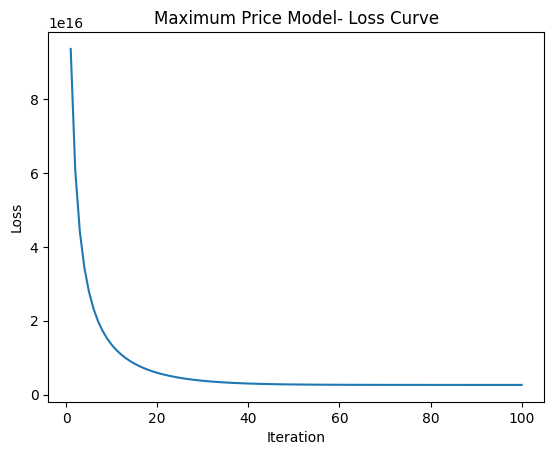

In [28]:
import matplotlib.pyplot as plt
plt.plot(range(1,101), losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Maximum Price Model- Loss Curve")
plt.show()

In [29]:
missing_years = [2012, 2013, 2014, 2015, 2016, 2017, 2018]

In [30]:
missing_years_max_prices = []

for i in range(len(missing_years)):
    predicted_price = predict(
        missing_years[i],
        theta0_max,
        theta1_max
    )

    missing_years_max_prices.append(predicted_price)

    print(missing_years[i], ":", predicted_price)

2012 : 35778.632421317656
2013 : 35796.41503744398
2014 : 35814.19765357031
2015 : 35831.98026969663
2016 : 35849.76288582296
2017 : 35867.54550194928
2018 : 35885.32811807561


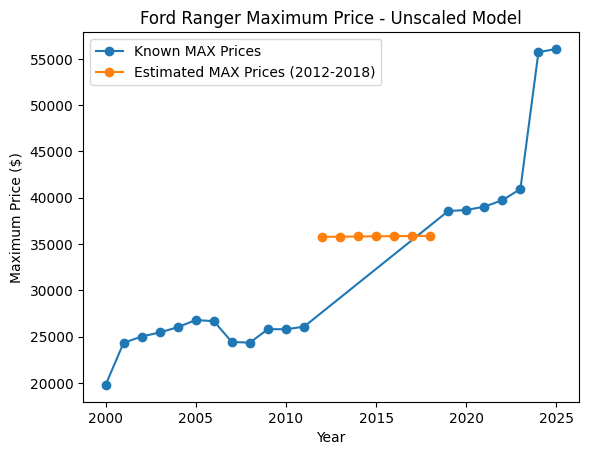

In [31]:
import matplotlib.pyplot as plt

plt.plot(
    years,
    max_prices,
    marker="o",
    label="Known MAX Prices"
)

plt.plot(
    missing_years,
    missing_years_max_prices,
    marker="o",
    label="Estimated MAX Prices (2012-2018)"
)

plt.xlabel("Year")
plt.ylabel("Maximum Price ($)")
plt.title("Ford Ranger Maximum Price - Unscaled Model")
plt.legend()

plt.show()

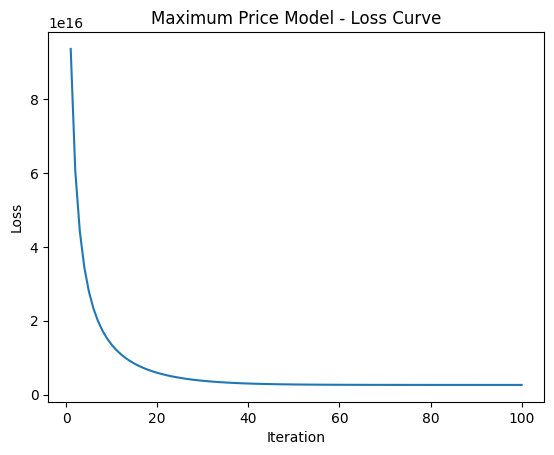

In [32]:
import matplotlib.pyplot as plt

plt.plot(range(1, 101), losses)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Maximum Price Model - Loss Curve")

plt.show()

### Unscaled MAX Model Observation

The unscaled MAX model also required a very small learning rate to remain stable. Its loss decreased across the 100 iterations, but the final loss was still relatively large.

Similar to the MIN model, this suggests that training directly with the original year values is possible, but it is not an efficient representation of the input for gradient descent.

## 4. Feature Scaling and Dynamic Learning Rate

After training the unscaled models, we repeated the experiment using feature scaling and a dynamic learning rate.

We standardized the year values using:

x_scaled = (x - mean) / standard deviation

This moves the year values from numbers around 2000 to much smaller values centered around zero. This makes the gradients easier to control during training.

We also used a dynamic learning rate:

alpha_current = alpha_start / (1 + decay * iteration)

The learning rate is therefore larger at the beginning of training and gradually becomes smaller as the number of iterations increases.

### 4.1 Scaled MIN-Price Model

In [33]:
mean_year = sum(years) / len(years)

In [34]:
variance = 0

for year in years:
    variance += (year - mean_year) ** 2

variance = variance / len(years)
std_year = variance ** 0.5

In [35]:
scaled_years = []

for year in years:
    scaled_year = (year - mean_year) / std_year
    scaled_years.append(scaled_year)

print("Mean:", mean_year)
print("Standard deviation:", std_year)
print("Scaled years:", scaled_years)

Mean: 2011.578947368421
Standard deviation: 8.505823327045663
Scaled years: [-1.3612964816238158, -1.243729967301759, -1.126163452979702, -1.008596938657645, -0.8910304243355881, -0.7734639100135311, -0.6558973956914742, -0.5383308813694172, -0.4207643670473603, -0.30319785272530336, -0.18563133840324642, -0.06806482408118945, 0.8724672904952662, 0.9900338048173231, 1.10760031913938, 1.225166833461437, 1.342733347783494, 1.460299862105551, 1.5778663764276077]


In [36]:
def train_dynamic(years, prices, theta0, theta1, learning_rate, iterations, decay):
    losses = []

    for i in range(iterations):

        current_learning_rate = learning_rate / (1 + decay * i)

        gradient_theta0, gradient_theta1 = gradients(
            years, prices, theta0, theta1
        )

        theta0 = theta0 - current_learning_rate * gradient_theta0
        theta1 = theta1 - current_learning_rate * gradient_theta1

        new_cost = cost(years, prices, theta0, theta1)
        losses.append(new_cost)

    return theta0, theta1, losses

In [37]:
theta0_scaled_min = 0
theta1_scaled_min = 0

learning_rate = 0.000000001
decay = 0.01

theta0_scaled_min, theta1_scaled_min, losses_scaled_min = train_dynamic(
    scaled_years,
    min_prices,
    theta0_scaled_min,
    theta1_scaled_min,
    learning_rate,
    100,
    decay
)

print("Final theta0:", theta0_scaled_min)
print("Final theta1:", theta1_scaled_min)
print("First loss:", losses_scaled_min[0])
print("Final loss:", losses_scaled_min[-1])

Final theta0: 15781.411743674294
Final theta1: 6998.363964755689
First loss: 7251196843585706.0
Final loss: 41114755130324.73


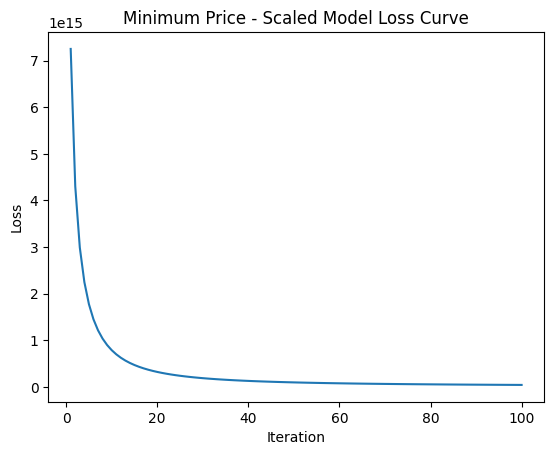

In [38]:
import matplotlib.pyplot as plt

plt.plot(range(1, 101), losses_scaled_min)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Minimum Price - Scaled Model Loss Curve")

plt.show()

In [39]:
missing_years = [2012, 2013, 2014, 2015, 2016, 2017, 2018]

scaled_missing_years = []

for year in missing_years:
    scaled_year = (year - mean_year) / std_year
    scaled_missing_years.append(scaled_year)

In [40]:
missing_min_prices_scaled = []

for i in range(len(scaled_missing_years)):

    predicted_price = predict(
        scaled_missing_years[i],
        theta0_scaled_min,
        theta1_scaled_min
    )

    missing_min_prices_scaled.append(predicted_price)

    print(
        missing_years[i],
        ":",
        predicted_price
    )

2012 : 16127.84258885048
2013 : 16950.615846143897
2014 : 17773.389103437315
2015 : 18596.16236073073
2016 : 19418.93561802415
2017 : 20241.708875317563
2018 : 21064.48213261098


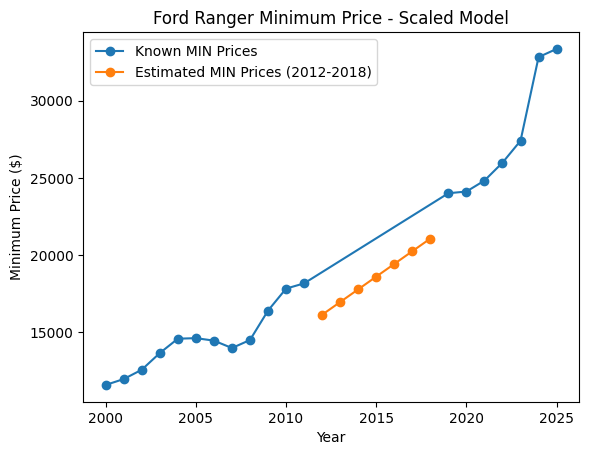

In [41]:
plt.plot(
    years,
    min_prices,
    marker="o",
    label="Known MIN Prices"
)

plt.plot(
    missing_years,
    missing_min_prices_scaled,
    marker="o",
    label="Estimated MIN Prices (2012-2018)"
)

plt.xlabel("Year")
plt.ylabel("Minimum Price ($)")
plt.title("Ford Ranger Minimum Price - Scaled Model")
plt.legend()

plt.show()

In [42]:
scaled_2026 = (2026 - mean_year) / std_year
predicted_min_2026 = predict(
    scaled_2026,
    theta0_scaled_min,
    theta1_scaled_min
)

print("Predicted MIN price for 2026:", predicted_min_2026)

Predicted MIN price for 2026: 27646.66819095832


### Scaled MIN Model Observation

The scaled MIN model produced a much lower final loss than the unscaled MIN model. Scaling the year feature allowed gradient descent to work with smaller input values instead of the original years around 2000.

The loss curve also shows that the model learned quickly during the earlier iterations and then changed more gradually as the dynamic learning rate decreased.

### 4.2 Scaled MAX-Price Model

In [43]:
# Find the center and spread of the years used for training
max_year_mean = sum(years) / len(years)

max_year_variance = 0

for year in years:
    difference = year - max_year_mean
    max_year_variance += difference ** 2

max_year_variance = max_year_variance / len(years)
max_year_std = max_year_variance ** 0.5

print("Average year:", max_year_mean)
print("Year standard deviation:", max_year_std)

Average year: 2011.578947368421
Year standard deviation: 8.505823327045663


In [44]:
# Scale each training year before using it in the MAX model
scaled_max_years = []

for year in years:
    scaled_year = (year - max_year_mean) / max_year_std
    scaled_max_years.append(scaled_year)

print("Scaled years:")
print(scaled_max_years)

Scaled years:
[-1.3612964816238158, -1.243729967301759, -1.126163452979702, -1.008596938657645, -0.8910304243355881, -0.7734639100135311, -0.6558973956914742, -0.5383308813694172, -0.4207643670473603, -0.30319785272530336, -0.18563133840324642, -0.06806482408118945, 0.8724672904952662, 0.9900338048173231, 1.10760031913938, 1.225166833461437, 1.342733347783494, 1.460299862105551, 1.5778663764276077]


In [45]:
def scaled_max_gradients(x_values, prices, theta0, theta1):

    theta0_gradient = 0
    theta1_gradient = 0

    for i in range(len(x_values)):

        prediction = theta0 + theta1 * x_values[i]
        year_error = prediction - prices[i]

        derivative = 2 * year_error + 0.4 * year_error ** 3

        theta0_gradient += derivative
        theta1_gradient += derivative * x_values[i]

    theta0_gradient = theta0_gradient / len(x_values)
    theta1_gradient = theta1_gradient / len(x_values)

    return theta0_gradient, theta1_gradient

In [46]:
def train_scaled_max(x_values, prices, theta0, theta1,
                     starting_rate, decay, iterations):

    scaled_max_losses = []

    for i in range(iterations):

        current_rate = starting_rate / (1 + decay * i)

        theta0_gradient, theta1_gradient = scaled_max_gradients(
            x_values, prices, theta0, theta1
        )

        theta0 = theta0 - current_rate * theta0_gradient
        theta1 = theta1 - current_rate * theta1_gradient

        total_cost = 0

        for j in range(len(x_values)):
            prediction = theta0 + theta1 * x_values[j]
            year_error = prediction - prices[j]

            total_cost += year_error ** 2 + 0.1 * year_error ** 4

        average_cost = total_cost / len(x_values)
        scaled_max_losses.append(average_cost)

    return theta0, theta1, scaled_max_losses

In [47]:
scaled_max_theta0 = 0
scaled_max_theta1 = 0

starting_rate = 0.000000001
decay = 0.01

scaled_max_theta0, scaled_max_theta1, scaled_max_losses = train_scaled_max(
    scaled_max_years,
    max_prices,
    scaled_max_theta0,
    scaled_max_theta1,
    starting_rate,
    decay,
    100
)

print("theta0:", scaled_max_theta0)
print("theta1:", scaled_max_theta1)
print("final loss:", scaled_max_losses[-1])

theta0: 31170.067498798297
theta1: 11095.820992310126
final loss: 85100241900864.94


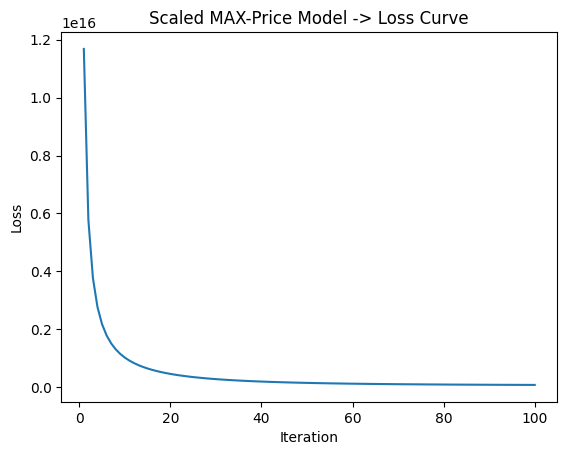

In [48]:
plt.plot(range(1, 101), scaled_max_losses)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Scaled MAX-Price Model -> Loss Curve")

plt.show()

In [49]:
missing_years = [
    2012, 2013, 2014, 2015,
    2016, 2017, 2018
]

scaled_max_missing_prices = []

for year in missing_years:

    scaled_year = (year - max_year_mean) / max_year_std

    estimated_price = (
        scaled_max_theta0 + scaled_max_theta1 * scaled_year
    )

    scaled_max_missing_prices.append(estimated_price)

    print(year, estimated_price)

2012 31719.329392527747
2013 33023.82639013515
2014 34328.32338774257
2015 35632.82038534997
2016 36937.31738295738
2017 38241.81438056479
2018 39546.3113781722


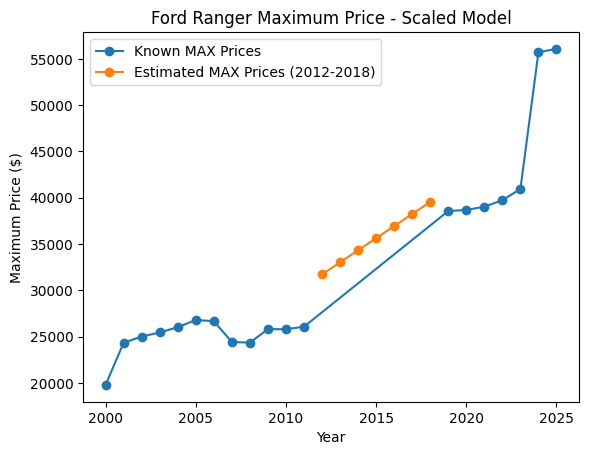

In [50]:
# Plot the MAX prices from the years included in the training data
plt.plot(
    years,
    max_prices,
    marker="o",
    label="Known MAX Prices"
)

# Add the estimated prices for the missing Ranger years
plt.plot(
    missing_years,
    scaled_max_missing_prices,
    marker="o",
    label="Estimated MAX Prices (2012-2018)"
)

plt.xlabel("Year")
plt.ylabel("Maximum Price ($)")
plt.title("Ford Ranger Maximum Price - Scaled Model")
plt.legend()

plt.show()

In [51]:
scaled_2026 = (2026 - mean_year) / std_year

predicted_max_2026 = predict(
    scaled_2026,
    scaled_max_theta0,
    scaled_max_theta1
)

print("Predicted MAX price for 2026:", predicted_max_2026)

Predicted MAX price for 2026: 49982.28735903147


In [52]:
print("Predicted 2026 price range: $",
      round(predicted_min_2026, 2),
      "- $",
      round(predicted_max_2026, 2))

Predicted 2026 price range: $ 27646.67 - $ 49982.29


### Scaled MAX Model Observation

The scaled MAX model showed the same general improvement. Its final loss was substantially lower than the loss from the unscaled MAX model.

This was important because it showed that simply decreasing the loss in the unscaled model was not enough. Changing the representation of the input feature made gradient descent much more effective.

## 5. Comparison of the Four Models

To compare the training behavior of the four models, we plotted their loss values over the same 100 iterations.

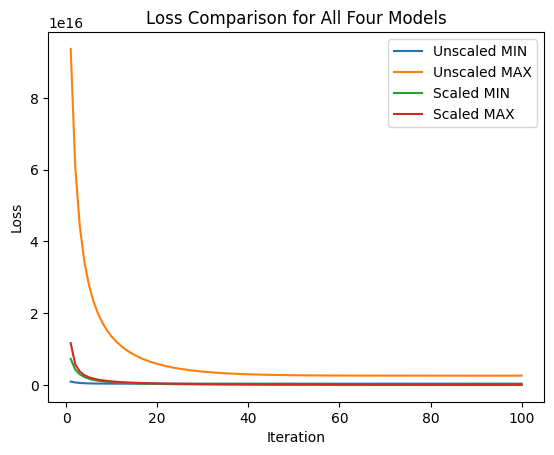

In [53]:
# Put all four training runs on the same plot for a direct comparison
plt.plot(
    range(1, 101),
    losses_unscaled_min,
    label="Unscaled MIN"
)

plt.plot(
    range(1, 101),
    losses_unscaled_max,
    label="Unscaled MAX"
)

plt.plot(
    range(1, 101),
    losses_scaled_min,
    label="Scaled MIN"
)

plt.plot(
    range(1, 101),
    scaled_max_losses,
    label="Scaled MAX"
)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Loss Comparison for All Four Models")
plt.legend()

plt.show()

All four models reduced their loss during training, but there is a clear difference between the scaled and unscaled results.

The unscaled models required extremely small learning rates because the original year values produced very large gradients. After scaling the year feature, both the MIN and MAX models reached much lower final losses.

For our dataset, scaling the input and using a dynamic learning rate made the optimization more effective. Because of this improvement, we used the scaled MIN and MAX models for our final 2026 price prediction.

## 6. Missing-Year Predictions: 2012-2018

The Ford Ranger was not produced in the U.S. from 2012 through 2018, so these years were not included in our training data.

After training each model, we used it to estimate prices for these missing years. These predictions help us see how each fitted regression line behaves inside the gap between the 2011 and 2019 data points.

The estimated values should not be interpreted as actual historical MSRP values. They are hypothetical prices generated by our models for years in which the Ranger was not produced.

## 7. 2026 Price Prediction

We left 2026 out of the training data so that we could use it as a separate prediction after training.

For the final 2026 estimate, we used the scaled MIN and MAX models because they reached lower final losses than their unscaled versions.

The predicted 2026 Ford Ranger price range is:

**$27,646.67 - $49,982.29**

This range should be treated as an estimate rather than an exact MSRP. Our models only use the model year as an input, while real vehicle prices are also affected by factors such as trim level, drivetrain, engine options, inflation, and changes between vehicle generations.

## 8. Discussion

The biggest difference we observed was between training with the original year values and training with scaled values. The unscaled models were able to reduce their loss, but they required extremely small learning rates because the year values caused very large gradients. After scaling the input, training became easier to control and both scaled models reached much lower final losses.

We also noticed that a decreasing loss does not necessarily mean that every prediction is close to the real price. This was especially clear when we compared some of the unscaled predictions with the actual data. Because of this, we looked at both the loss curves and the year-to-price plots instead of judging the models only by their final loss.

One limitation of our models is that year is the only input feature. In reality, the price of a Ford Ranger can also depend on trim level, engine and drivetrain options, inflation, market conditions, and changes between vehicle generations. Our models do not include any of these factors.

If we continued improving this project, we would include additional vehicle features and more pricing data. We would also separate some data from training and use it to evaluate how well the model performs on unseen examples.

### Would We Buy a 2026 Ford Ranger Based on This Model?

We would not make a purchasing decision based only on this model.

The predicted range gives us an idea of where the price could be, but the model does not contain enough information to decide whether the vehicle itself is a good purchase. We would also want to compare the actual MSRP, trim level, features, reliability, and other vehicles available in the same price range.

For us, the prediction would be useful as a reference point, but not as the only reason to buy the vehicle.

## 9. Conclusion

In this assignment, we implemented linear regression and gradient descent from scratch to model the minimum and maximum prices of the Ford Ranger.

We first trained two models using the original year values and fixed learning rates. We then repeated the process after scaling the year feature and using dynamic learning rates. The scaled models reached lower final losses, which showed us that scaling made gradient descent more effective for this dataset.

We also used the models to estimate prices for the missing 2012-2018 period and used the scaled models to predict a possible 2026 price range.

One thing we learned from this experiment is that a decreasing loss does not automatically mean that every prediction is accurate. The loss curves helped us understand the training process, while comparing the predicted prices with the actual data helped us see the limitations of using only year as a feature.

Overall, this assignment helped us understand not only how linear regression and gradient descent work mathematically, but also how choices such as feature scaling and learning rate can affect the training process.